# LaTeX font: `font_latex`

Compare `L"..."` text from Makierc with matplotlib's `mathtext.fontset: stix`.

Open this notebook with `test/` as the working directory and run all cells.

In [1]:
using Pkg
Pkg.activate(temp = true)
Pkg.develop(path = "..")
Pkg.add("CairoMakie")

using CairoMakie, Makierc

In [2]:
samples = [
    L"\alpha\beta\gamma\,x^2_i + \mathrm{ab}\,\mathbf{P}\,-1.25\;(E)\;\Lambda\Sigma",
    L"\sum_{n=0}^{\infty} \int_0^1 \sqrt{s}\,\frac{g^2}{s-m^2}\,dx \leq \pi\hbar",
    L"|T(s)|^2\;\mathrm{MeV}\;K^{*}\bar{D}\,\to\,\pi\pi",
]

# 24 pt at 100 dpi in matplotlib is about 33 px, so the two pictures have the same scale.
function show_samples()
    fig = Figure(size = (800, 320), backgroundcolor = :white)
    ax = Axis(fig[1, 1])
    hidedecorations!(ax)
    hidespines!(ax)
    limits!(ax, 0, 1, 0, 1)
    for (i, s) in enumerate(samples)
        text!(ax, 0.02, 0.82 - (i - 1) * 0.32; text = s, fontsize = 33, align = (:left, :center))
    end
    return fig
end

show_samples (generic function with 1 method)

## Makierc default: `font_latex = "STIX"`

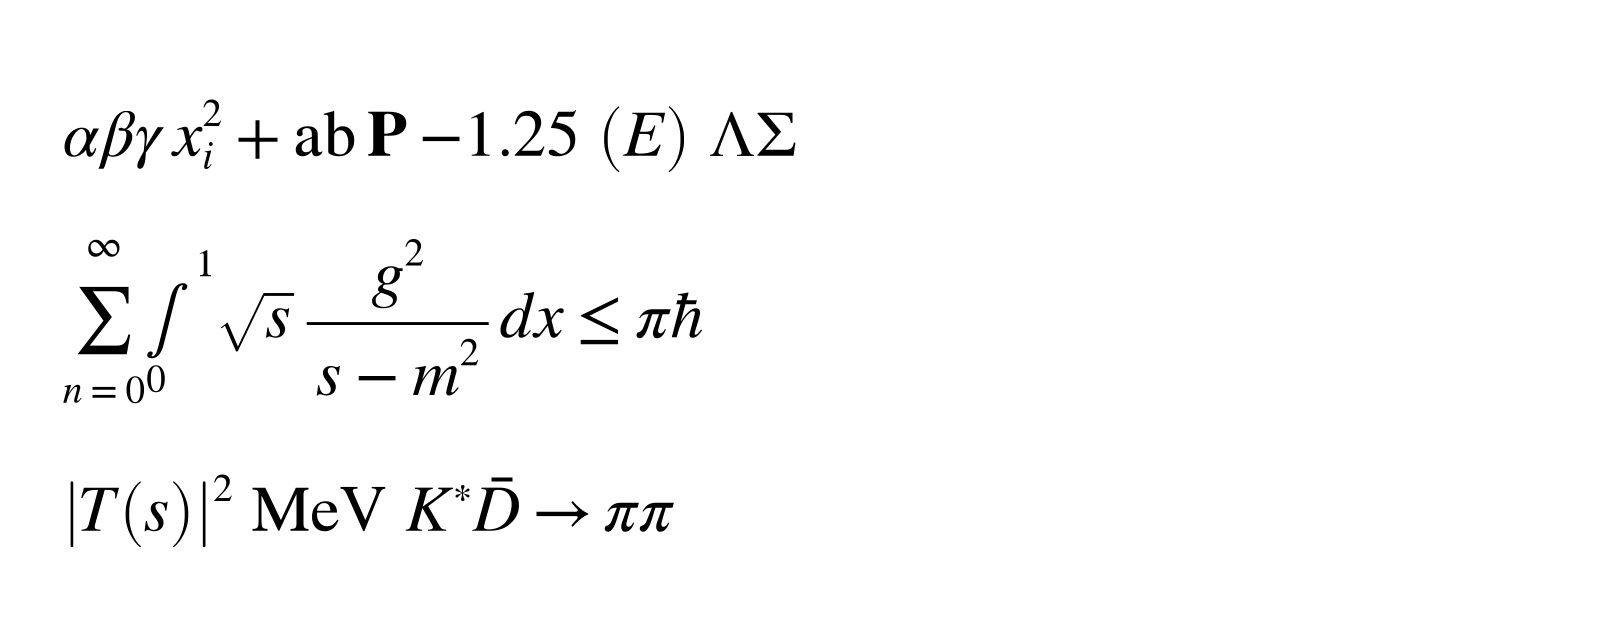

In [3]:
load_makie_config!()
show_samples()

## Matplotlib reference

`latex_font_matplotlib.png` was made with `mathtext.fontset: stix`, `fontsize = 24` and `dpi = 100`.

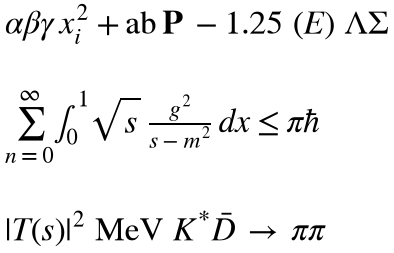

In [4]:
display(MIME("image/png"), read("latex_font_matplotlib.png"))

## For comparison: Makie's default, `font_latex = "NewComputerModern"`

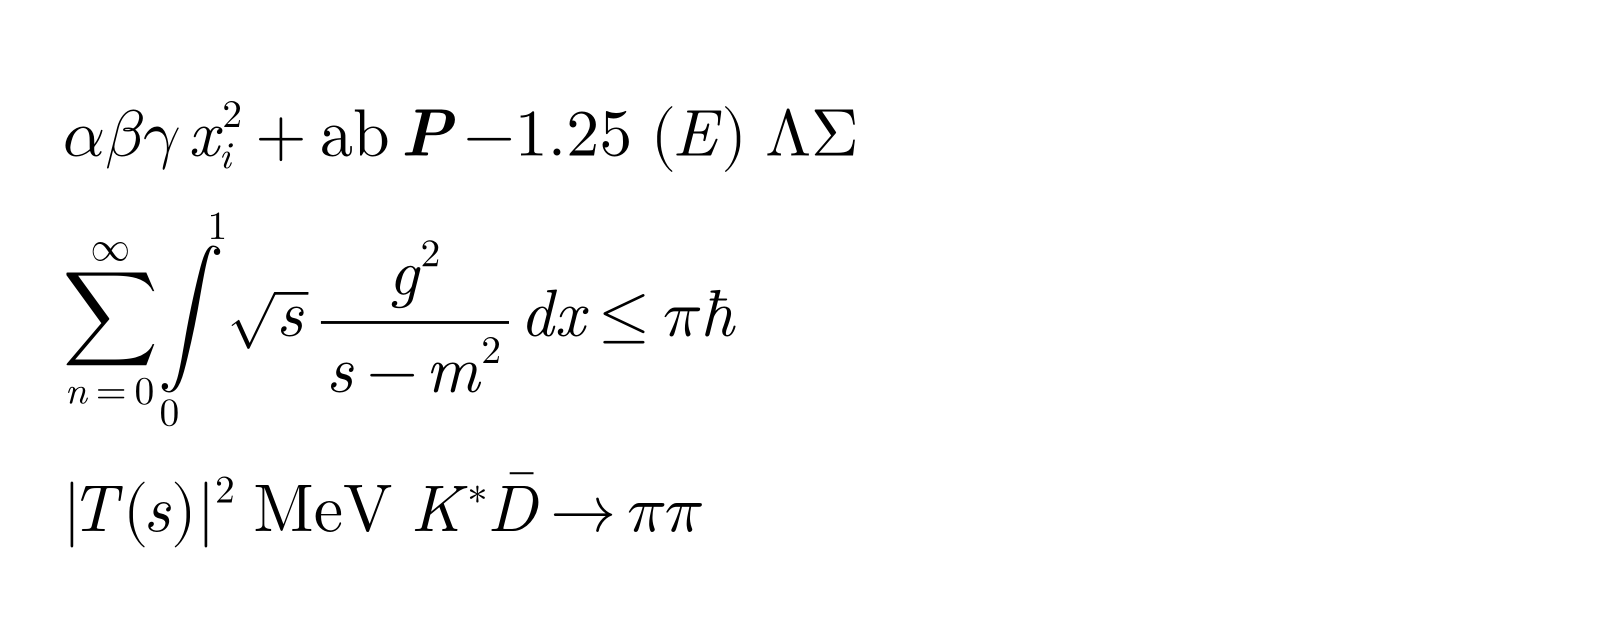

In [5]:
load_makie_config!(font_latex = "NewComputerModern")
show_samples()

## In a real plot

The labels use `font_latex`. The title, tick labels and other normal text use `font_regular`.

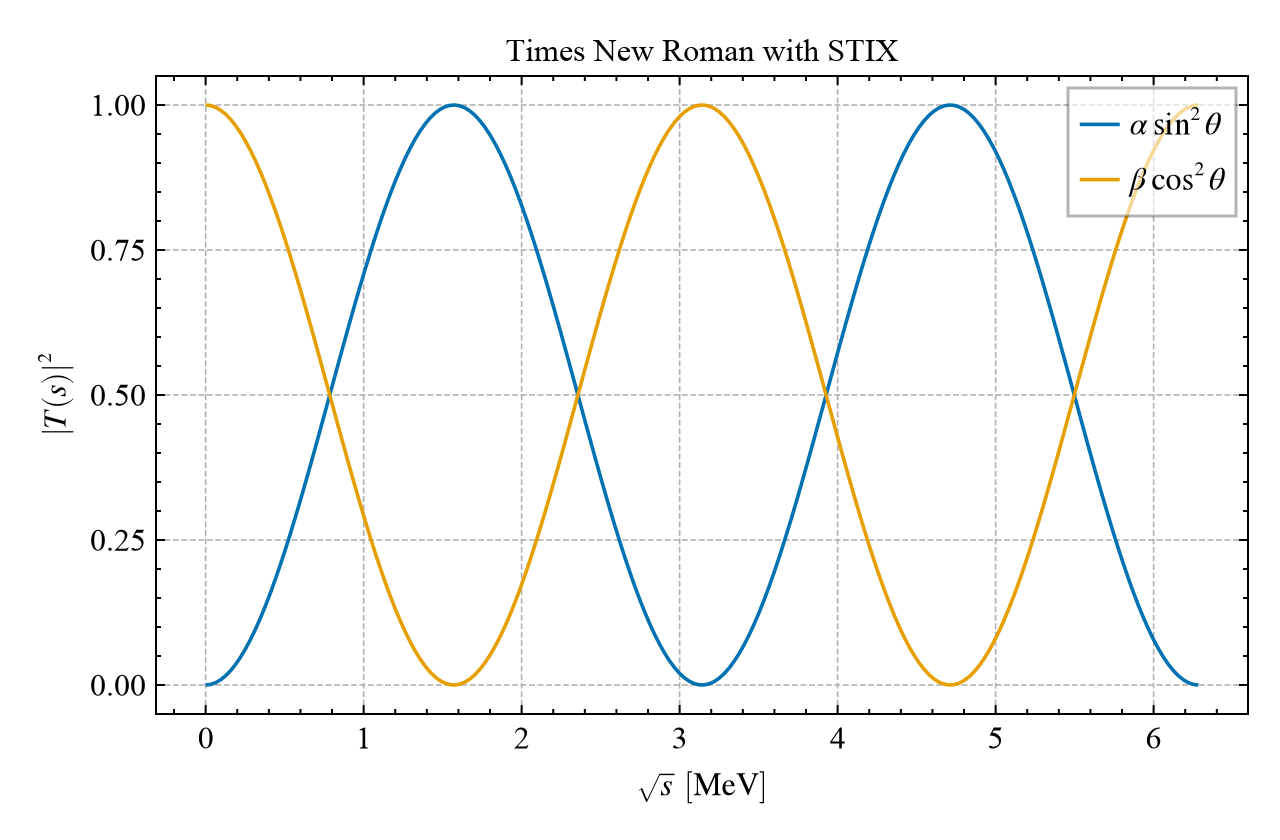

In [6]:
load_makie_config!()

fig = Figure(size = (640, 420), backgroundcolor = :white)
ax = Axis(fig[1, 1];
    xlabel = L"\sqrt{s}\;[\mathrm{MeV}]",
    ylabel = L"|T(s)|^2",
    title = "Times New Roman with STIX")
x = range(0, 2π, 200)
lines!(ax, x, sin.(x) .^ 2; label = L"\alpha\,\sin^2\theta")
lines!(ax, x, cos.(x) .^ 2; label = L"\beta\,\cos^2\theta")
axislegend(ax)
fig